In [37]:
#Nama : muhammad Deny Azes Saputra
#NIM:TI22250028
#Tahap 1 Data Udersatanding
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [38]:
# untuk Membaca dataset
df_raw = pd.read_csv('original.csv')

# Membersihkan nama kolom
df_raw.columns = df_raw.columns.str.strip()

# Menampilkan ukuran dataset awal
print("Ukuran dataset awal:", df_raw.shape)

# Menghapus baris dan kolom yang seluruhnya kosong
df = df_raw.dropna(how='all')
df = df.dropna(axis=1, how='all')

print("Ukuran dataset setelah dibersihkan:", df.shape)

Ukuran dataset awal: (87, 22)
Ukuran dataset setelah dibersihkan: (80, 20)


In [3]:
# Menampilkan 5 data pertama
display(df.head())

# Melihat informasi dataset
df.info()

,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,TUNDRA LSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Percent Attended,"label (fail=1, pass=0)"
0,0.0,38.0,5.0,5.0,4.0,5.0,4.0,4.0,5.0,5.0,0.0,1.0,13.333806,19.0,7.41,0.620767,3.0,9.0,25.000000,1.0
1,0.0,22.0,4.0,2.0,1.0,3.0,4.0,4.0,4.0,5.0,0.0,1.0,15.844126,1.0,0.03,0.002513,0.0,12.0,0.000000,1.0
2,0.0,21.0,4.0,5.0,4.0,5.0,4.0,4.0,5.0,5.0,0.0,1.0,17.706573,25.0,6.14,0.514374,5.0,7.0,41.666667,1.0
3,0.0,25.0,5.0,4.0,3.0,4.0,3.0,3.0,5.0,5.0,0.0,0.0,17.327498,3.0,0.16,0.013404,0.0,12.0,0.000000,1.0
4,0.0,20.0,5.0,4.0,3.0,4.0,3.0,3.0,4.0,4.0,0.0,1.0,0.000000,25.0,4.03,0.337610,11.0,1.0,91.666667,1.0


<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Gender                             80 non-null     float64
 1   Age                                80 non-null     float64
 2   POLAR4 Quintile                    80 non-null     float64
 3   POLAR3 Quintile                    80 non-null     float64
 4   Adult HE 2001 Quintile             80 non-null     float64
 5   Adult HE 2011 Quintile             80 non-null     float64
 6   TUNDRA MSOA Quintile               80 non-null     float64
 7   TUNDRA LSOA Quintile               80 non-null     float64
 8   Gaps GCSE Quintile                 80 non-null     float64
 9   Gaps GCSE Ethnicity Quintile       80 non-null     float64
 10  Uni Connect target ward            80 non-null     float64
 11  attending from home?               80 non-null     float64
 12  distanc

Jumlah mahasiswa:
Lulus (0): 68
Gagal (1): 12


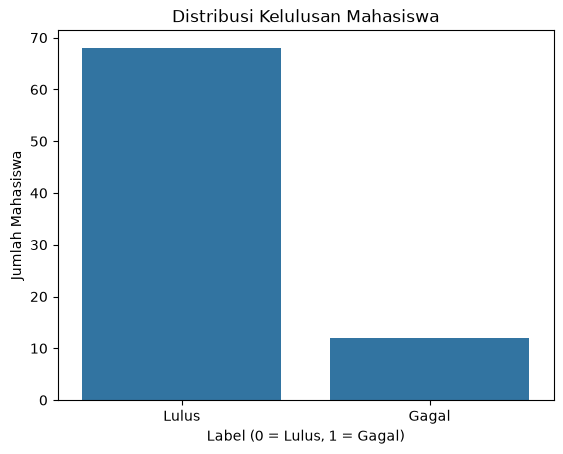

In [4]:
# Menghitung jumlah setiap label
jumlah_label = df['label (fail=1, pass=0)'].value_counts().sort_index()

print("Jumlah mahasiswa:")
print("Lulus (0):", jumlah_label.get(0, 0))
print("Gagal (1):", jumlah_label.get(1, 0))

# Visualisasi distribusi label
sns.countplot(
    data=df,
    x='label (fail=1, pass=0)'
)

plt.title('Distribusi Kelulusan Mahasiswa')
plt.xlabel('Label (0 = Lulus, 1 = Gagal)')
plt.ylabel('Jumlah Mahasiswa')
plt.xticks([0, 1], ['Lulus', 'Gagal'])
plt.show()

In [35]:
#Eda dan procesing (eksplorasi dan pembersihan data)
# Memeriksa data kosong
print("Jumlah data kosong setiap kolom:")
print(df.isnull().sum())

# Menghitung seluruh data kosong
print("\nTotal data kosong:", df.isnull().sum().sum())

# Memeriksa data duplikat
print("\nJumlah data duplikat:", df.duplicated().sum())

# Memeriksa baris dan kolom yang seluruhnya kosong
print("Baris kosong seluruhnya:", df.isna().all(axis=1).sum())
print("Kolom kosong seluruhnya:", df.isna().all(axis=0).sum())

Jumlah data kosong setiap kolom:
Gender                               0
Age                                  0
POLAR4 Quintile                      0
POLAR3 Quintile                      0
Adult HE 2001 Quintile               0
Adult HE 2011 Quintile               0
TUNDRA MSOA Quintile                 0
TUNDRA LSOA Quintile                 0
Gaps GCSE Quintile                   0
Gaps GCSE Ethnicity Quintile         0
Uni Connect target ward              0
attending from home?                 0
distance to university (km)          0
Count of Module Area Logins          0
Total Hours in Module Area           0
% of Average Hours in Module Area    0
# of presence                        0
# of Absence                         0
Percent Attended                     0
label (fail=1, pass=0)               0
dtype: int64

Total data kosong: 0

Jumlah data duplikat: 0
Baris kosong seluruhnya: 0
Kolom kosong seluruhnya: 0


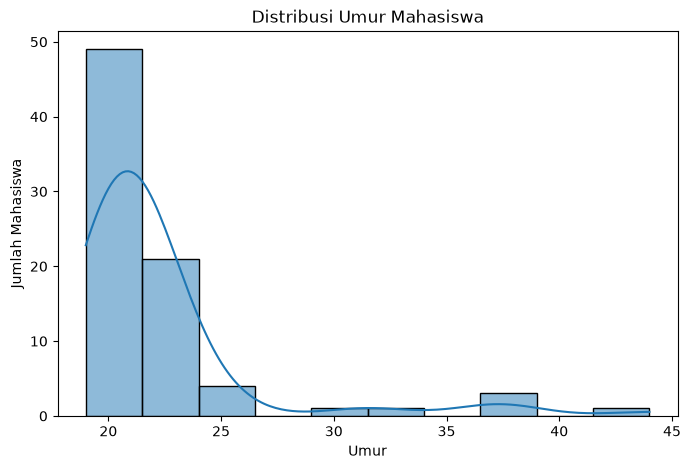

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Age', bins=10, kde=True)

plt.title('Distribusi Umur Mahasiswa')
plt.xlabel('Umur')
plt.ylabel('Jumlah Mahasiswa')
plt.show()

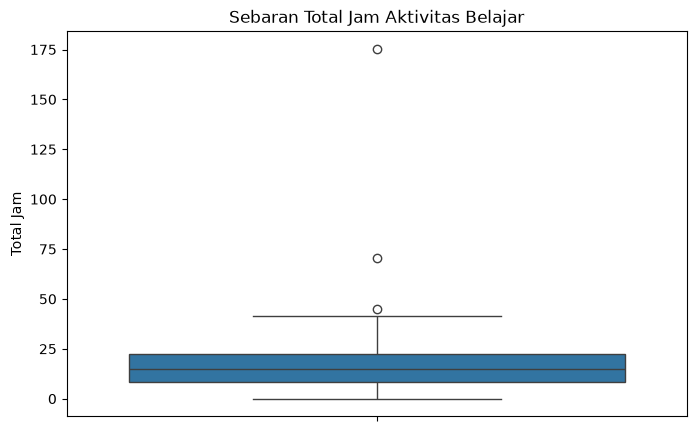

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, y='Total Hours in Module Area')

plt.title('Sebaran Total Jam Aktivitas Belajar')
plt.ylabel('Total Jam')
plt.show()

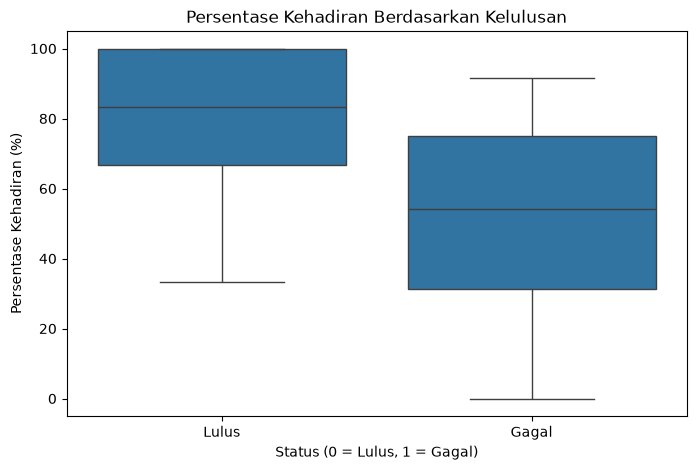

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='label (fail=1, pass=0)',
    y='Percent Attended'
)

plt.title('Persentase Kehadiran Berdasarkan Kelulusan')
plt.xlabel('Status (0 = Lulus, 1 = Gagal)')
plt.ylabel('Persentase Kehadiran (%)')
plt.xticks([0, 1], ['Lulus', 'Gagal'])
plt.show()

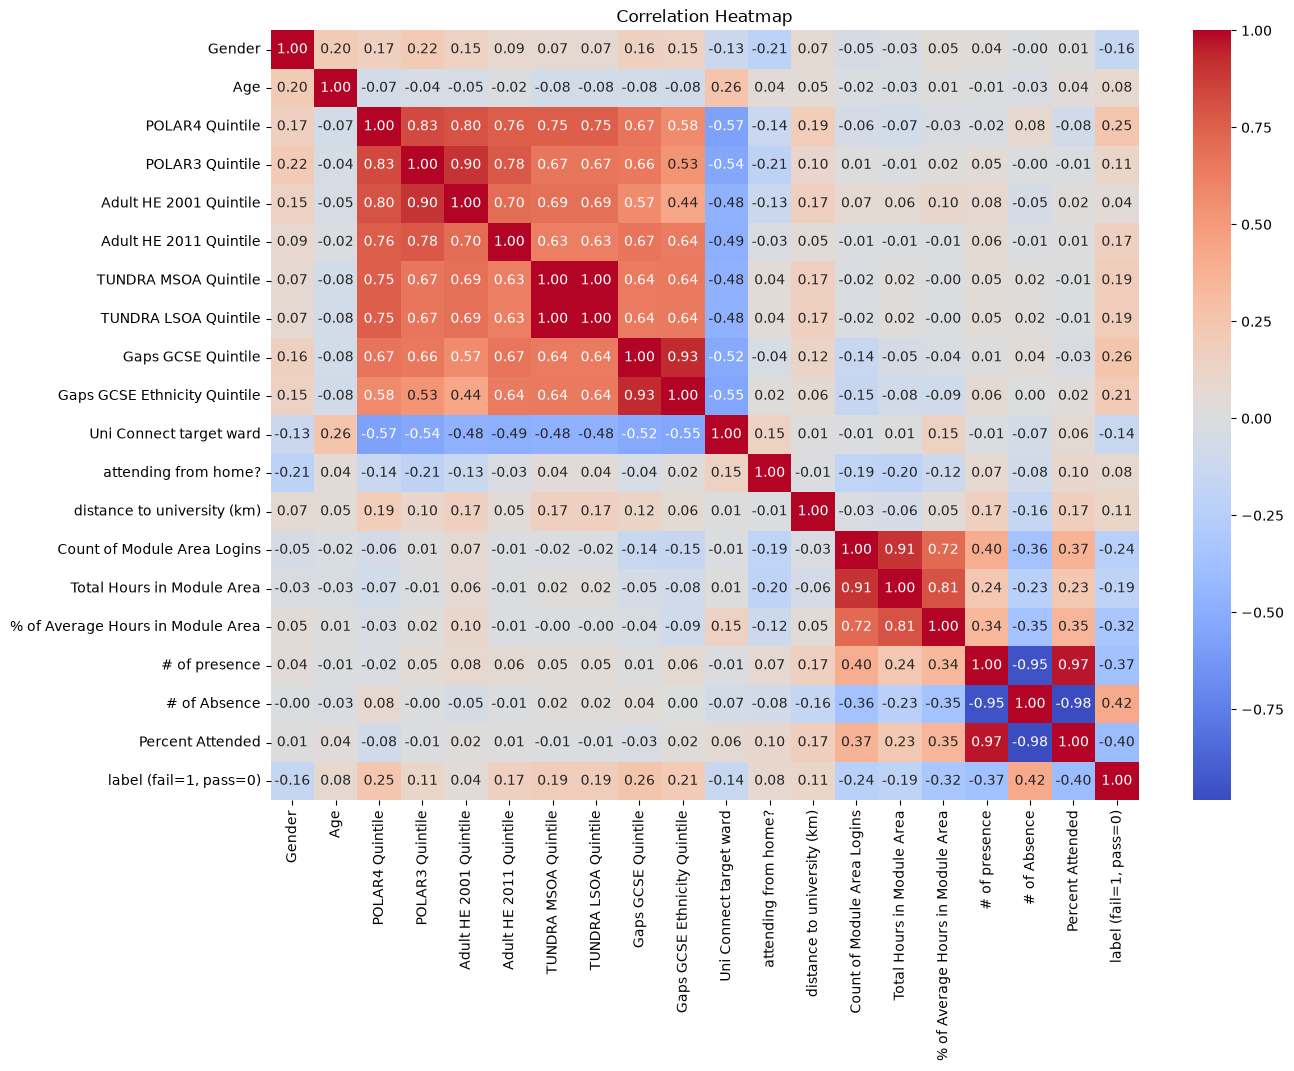

In [9]:
plt.figure(figsize=(14, 10))

korelasi = df.corr(numeric_only=True)

sns.heatmap(
    korelasi,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [10]:
# Memeriksa jumlah nilai 0 pada setiap kolom Quintile

kolom_quintile = [kolom for kolom in df.columns if 'Quintile' in kolom]

for kolom in kolom_quintile:
    jumlah_nol = (df[kolom] == 0).sum()
    print(kolom, ":", jumlah_nol)

POLAR4 Quintile : 0
POLAR3 Quintile : 0
Adult HE 2001 Quintile : 0
Adult HE 2011 Quintile : 2
TUNDRA MSOA Quintile : 2
TUNDRA LSOA Quintile : 2
Gaps GCSE Quintile : 4
Gaps GCSE Ethnicity Quintile : 4


In [11]:
# Memeriksa outlier menggunakan metode IQR

kolom_numerik = [
    'Age',
    'distance to university (km)',
    'Count of Module Area Logins',
    'Total Hours in Module Area',
    '% of Average Hours in Module Area',
    '# of presence',
    '# of Absence'
]

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    print(kolom, ":", jumlah_outlier, "outlier")

Age : 6 outlier
distance to university (km) : 7 outlier
Count of Module Area Logins : 2 outlier
Total Hours in Module Area : 3 outlier
% of Average Hours in Module Area : 4 outlier
# of presence : 2 outlier
# of Absence : 2 outlier


In [12]:
# Menghitung median pada kolom jumlah ketidakhadiran
median_absence = df['# of Absence'].median()

print("Nilai median:", median_absence)

# Mengisi data kosong dengan median
df['# of Absence'] = df['# of Absence'].fillna(median_absence)

# Memeriksa kembali data kosong
print("\nJumlah data kosong setelah penanganan:")
print(df.isnull().sum())

Nilai median: 2.0

Jumlah data kosong setelah penanganan:
Gender                               0
Age                                  0
POLAR4 Quintile                      0
POLAR3 Quintile                      0
Adult HE 2001 Quintile               0
Adult HE 2011 Quintile               0
TUNDRA MSOA Quintile                 0
TUNDRA LSOA Quintile                 0
Gaps GCSE Quintile                   0
Gaps GCSE Ethnicity Quintile         0
Uni Connect target ward              0
attending from home?                 0
distance to university (km)          0
Count of Module Area Logins          0
Total Hours in Module Area           0
% of Average Hours in Module Area    0
# of presence                        0
# of Absence                         0
Percent Attended                     0
label (fail=1, pass=0)               0
dtype: int64


In [34]:
#Tahap 3 Data preparation (persiapan data)
# Menentukan kolom target
target_col = 'label (fail=1, pass=0)'

# Membuat salinan dataset untuk pemodelan
data_model = df.copy()

# Mengubah nilai 0 pada kolom Quintile menjadi NaN
kolom_quintile = [
    kolom for kolom in data_model.columns
    if 'Quintile' in kolom
]

data_model[kolom_quintile] = data_model[kolom_quintile].replace(0, np.nan)

# Menghapus fitur yang berulang
data_model = data_model.drop(
    columns=['TUNDRA LSOA Quintile', 'Percent Attended']
)

# Memisahkan fitur dan target
X = data_model.drop(columns=[target_col])
y = data_model[target_col].astype(int)

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])

print("\nDaftar fitur:")
print(X.columns.tolist())

Jumlah fitur: 17
Jumlah data: 80

Daftar fitur:
['Gender', 'Age', 'POLAR4 Quintile', 'POLAR3 Quintile', 'Adult HE 2001 Quintile', 'Adult HE 2011 Quintile', 'TUNDRA MSOA Quintile', 'Gaps GCSE Quintile', 'Gaps GCSE Ethnicity Quintile', 'Uni Connect target ward', 'attending from home?', 'distance to university (km)', 'Count of Module Area Logins', 'Total Hours in Module Area', '% of Average Hours in Module Area', '# of presence', '# of Absence']


In [14]:
# Membagi data training dan testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

print("\nDistribusi label training:")
print(y_train.value_counts())

print("\nDistribusi label testing:")
print(y_test.value_counts())

Jumlah data training: 64
Jumlah data testing: 16

Distribusi label training:
label (fail=1, pass=0)
0    54
1    10
Name: count, dtype: int64

Distribusi label testing:
label (fail=1, pass=0)
0    14
1     2
Name: count, dtype: int64


In [15]:
# Memeriksa distribusi label data training

jumlah_kelas = y_train.value_counts().sort_index()

print("Distribusi kelas training:")
print("Lulus (0):", jumlah_kelas.get(0, 0))
print("Gagal (1):", jumlah_kelas.get(1, 0))

print("\nPersentase setiap kelas:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Distribusi kelas training:
Lulus (0): 54
Gagal (1): 10

Persentase setiap kelas:
label (fail=1, pass=0)
0    84.38
1    15.62
Name: proportion, dtype: float64


In [33]:
#Tahap 4 Modeling (Pembuatan Model)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

print("Library modeling berhasil diimpor.")

Library modeling berhasil diimpor.


In [17]:
# Membuat model Logistic Regression

model_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

print("Model Logistic Regression berhasil dibuat.")

Model Logistic Regression berhasil dibuat.


In [18]:
# Membuat Cross Validation 5 lipatan

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Menguji Logistic Regression
scores_lr = cross_val_score(
    model_lr,
    X_train,
    y_train,
    cv=cv,
    scoring='f1'
)

print("Hasil F1 Score Logistic Regression:")
print(scores_lr)

print("\nRata-rata F1 Score:",
      round(scores_lr.mean(), 4))

Hasil F1 Score Logistic Regression:
[0.57142857 0.5        0.4        0.57142857 0.66666667]

Rata-rata F1 Score: 0.5419


In [19]:
# Membuat model Random Forest

model_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

print("Model Random Forest berhasil dibuat.")

Model Random Forest berhasil dibuat.


In [20]:
# Menentukan kombinasi parameter yang akan diuji

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 3, 5],
    'classifier__min_samples_split': [2, 4]
}

# Melakukan Hyperparameter Tuning

grid_rf = GridSearchCV(
    estimator=model_rf,
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Parameter terbaik:")
print(grid_rf.best_params_)

print("\nF1 Score terbaik:")
print(round(grid_rf.best_score_, 4))

Parameter terbaik:
{'classifier__max_depth': 5, 'classifier__min_samples_split': 4, 'classifier__n_estimators': 100}

F1 Score terbaik:
0.4933


In [21]:
# Membandingkan hasil kedua model

hasil_perbandingan = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest'
    ],
    'Rata-rata F1 Score': [
        scores_lr.mean(),
        grid_rf.best_score_
    ]
})

display(hasil_perbandingan)

# Menentukan model dengan F1 Score tertinggi
if scores_lr.mean() > grid_rf.best_score_:
    print("Model terbaik berdasarkan Cross Validation: Logistic Regression")
else:
    print("Model terbaik berdasarkan Cross Validation: Random Forest")

,Model,Rata-rata F1 Score
0,Logistic Regression,0.541905
1,Random Forest,0.493333


Model terbaik berdasarkan Cross Validation: Logistic Regression


In [32]:
#Tahap 5 -evaluation(evaluasi model)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Melatih Logistic Regression
model_lr.fit(X_train, y_train)

# Mengambil model Random Forest terbaik
best_rf = grid_rf.best_estimator_

# Membuat prediksi pada data testing
pred_lr = model_lr.predict(X_test)
pred_rf = best_rf.predict(X_test)

print("Prediksi kedua model berhasil dibuat.")

Prediksi kedua model berhasil dibuat.


In [23]:
# Menghitung evaluasi Logistic Regression
akurasi_lr = accuracy_score(y_test, pred_lr)
presisi_lr = precision_score(y_test, pred_lr, zero_division=0)
recall_lr = recall_score(y_test, pred_lr, zero_division=0)
f1_lr = f1_score(y_test, pred_lr, zero_division=0)

# Menghitung evaluasi Random Forest
akurasi_rf = accuracy_score(y_test, pred_rf)
presisi_rf = precision_score(y_test, pred_rf, zero_division=0)
recall_rf = recall_score(y_test, pred_rf, zero_division=0)
f1_rf = f1_score(y_test, pred_rf, zero_division=0)

# Menampilkan hasil evaluasi
hasil_evaluasi = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [akurasi_lr, akurasi_rf],
    'Precision': [presisi_lr, presisi_rf],
    'Recall': [recall_lr, recall_rf],
    'F1 Score': [f1_lr, f1_rf]
})

display(hasil_evaluasi.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8125,0.3333,0.5,0.4000
1,Random Forest,0.9375,1.0000,0.5,0.6667


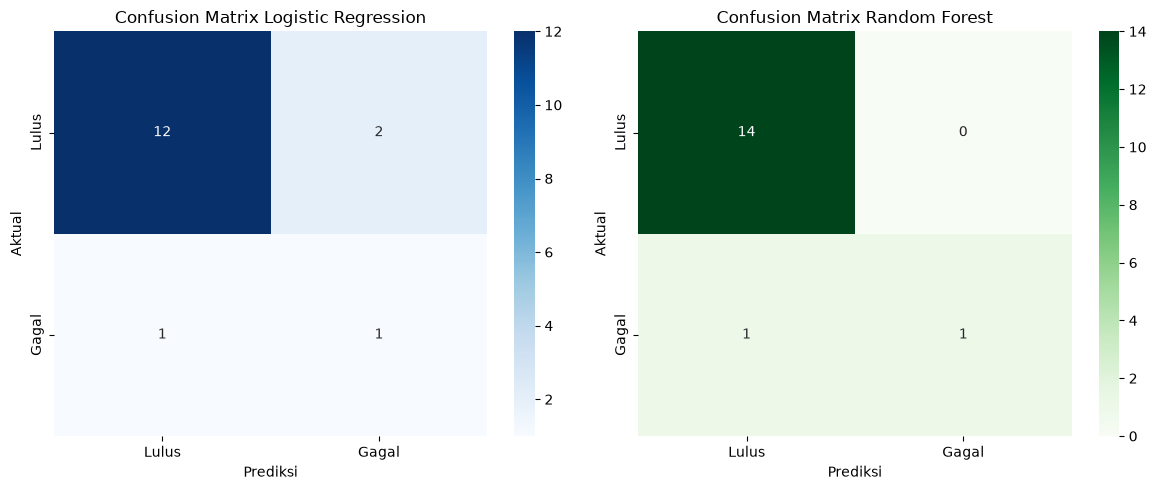

In [24]:
# Membuat Confusion Matrix

cm_lr = confusion_matrix(y_test, pred_lr, labels=[0, 1])
cm_rf = confusion_matrix(y_test, pred_rf, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_lr, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Lulus', 'Gagal'],
    yticklabels=['Lulus', 'Gagal'],
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix Logistic Regression')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

sns.heatmap(
    cm_rf, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Lulus', 'Gagal'],
    yticklabels=['Lulus', 'Gagal'],
    ax=axes[1]
)
axes[1].set_title('Confusion Matrix Random Forest')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

10 Fitur Paling Berpengaruh:


% of Average Hours in Module Area    0.262854
Count of Module Area Logins          0.174591
Total Hours in Module Area           0.123564
# of Absence                         0.091559
distance to university (km)          0.057828
# of presence                        0.054639
POLAR4 Quintile                      0.054385
Adult HE 2011 Quintile               0.040487
POLAR3 Quintile                      0.029185
Age                                  0.028524
dtype: float64

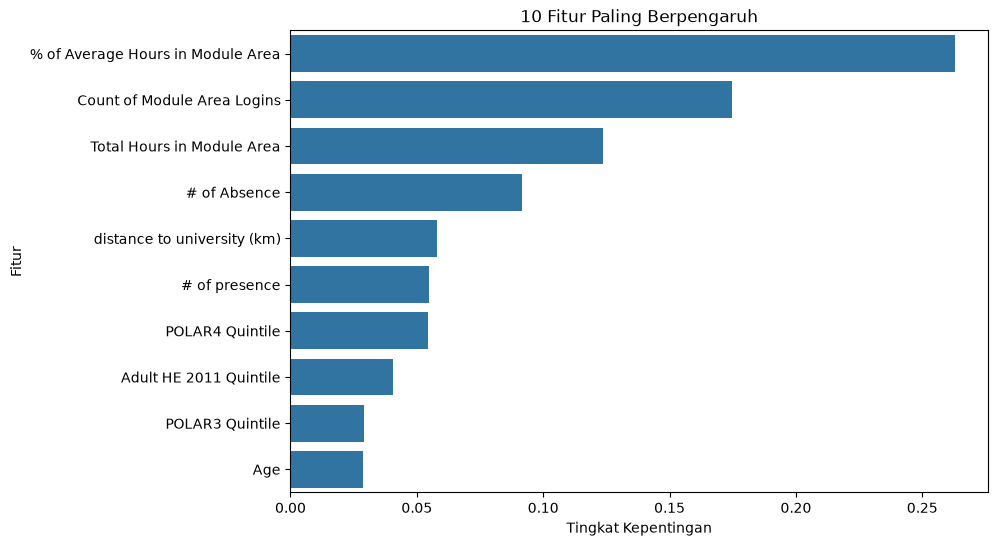

In [25]:
# Mengambil nilai feature importance dari Random Forest

rf_classifier = best_rf.named_steps['classifier']

feature_importance = pd.Series(
    rf_classifier.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

# Menampilkan 10 fitur paling berpengaruh
print("10 Fitur Paling Berpengaruh:")
display(feature_importance.head(10))

# Membuat grafik feature importance
plt.figure(figsize=(9, 6))

sns.barplot(
    x=feature_importance.head(10).values,
    y=feature_importance.head(10).index
)

plt.title('10 Fitur Paling Berpengaruh')
plt.xlabel('Tingkat Kepentingan')
plt.ylabel('Fitur')
plt.show()

In [26]:
# Laporan evaluasi Logistic Regression
print("LOGISTIC REGRESSION")
print(classification_report(
    y_test,
    pred_lr,
    target_names=['Lulus', 'Gagal'],
    zero_division=0
))

# Laporan evaluasi Random Forest
print("RANDOM FOREST")
print(classification_report(
    y_test,
    pred_rf,
    target_names=['Lulus', 'Gagal'],
    zero_division=0
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

       Lulus       0.92      0.86      0.89        14
       Gagal       0.33      0.50      0.40         2

    accuracy                           0.81        16
   macro avg       0.63      0.68      0.64        16
weighted avg       0.85      0.81      0.83        16

RANDOM FOREST
              precision    recall  f1-score   support

       Lulus       0.93      1.00      0.97        14
       Gagal       1.00      0.50      0.67         2

    accuracy                           0.94        16
   macro avg       0.97      0.75      0.82        16
weighted avg       0.94      0.94      0.93        16



In [31]:
#Tahap 6 Random prediction test(pengujian prediksi data baru)
# Menentukan model terbaik

if f1_lr >= f1_rf:
    model_terbaik = model_lr
    nama_model = "Logistic Regression"
else:
    model_terbaik = best_rf
    nama_model = "Random Forest"

print("Model terbaik:", nama_model)

Model terbaik: Random Forest


In [28]:
# Membuat data mahasiswa baru secara acak

rng = np.random.default_rng(42)

data_baru = pd.DataFrame(index=range(5), columns=X.columns)

for kolom in X.columns:
    if kolom in ['Gender', 'Uni Connect target ward',
                 'attending from home?']:
        data_baru[kolom] = rng.choice([0, 1], size=5)

    elif 'Quintile' in kolom:
        data_baru[kolom] = rng.integers(1, 6, size=5)

    elif kolom == 'Age':
        data_baru[kolom] = rng.integers(19, 45, size=5)

    elif kolom == 'distance to university (km)':
        data_baru[kolom] = rng.uniform(
            df[kolom].min(), df[kolom].max(), size=5
        )

    elif kolom == 'Count of Module Area Logins':
        data_baru[kolom] = rng.integers(1, 336, size=5)

    elif kolom == 'Total Hours in Module Area':
        data_baru[kolom] = rng.uniform(
            df[kolom].min(), df[kolom].max(), size=5
        )

    elif kolom == '% of Average Hours in Module Area':
        data_baru[kolom] = rng.uniform(
            df[kolom].min(), df[kolom].max(), size=5
        )

    elif kolom == '# of presence':
        data_baru[kolom] = rng.integers(0, 14, size=5)

# Membuat jumlah ketidakhadiran yang sesuai
data_baru['# of Absence'] = np.maximum(
    0, 12 - data_baru['# of presence']
)

display(data_baru)

,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence
0,0,41,3,4,3,4,3,1,1,1,1,48.960278,15,33.265171,2.407337,6,6
1,1,21,5,3,2,3,2,5,4,0,0,216.750123,304,22.819531,4.583173,11,1
2,1,37,4,1,1,5,1,5,4,1,0,236.333411,125,83.473401,3.854753,11,1
3,0,24,4,5,5,3,3,2,2,1,0,307.017312,26,39.832169,1.720879,5,7
4,0,21,4,3,4,3,5,4,1,1,0,103.393302,158,117.522073,4.580872,12,0


In [29]:
# Melakukan prediksi mahasiswa baru

prediksi = model_terbaik.predict(data_baru)

# Menghitung probabilitas setiap kelas
probabilitas = model_terbaik.predict_proba(data_baru)

# Mengambil probabilitas kelas gagal (1)
posisi_gagal = list(model_terbaik.classes_).index(1)

prob_gagal = probabilitas[:, posisi_gagal] * 100

# Membuat tabel hasil prediksi
hasil_prediksi = data_baru.copy()

hasil_prediksi['Hasil Prediksi'] = np.where(
    prediksi == 1,
    'Gagal',
    'Lulus'
)

hasil_prediksi['Probabilitas Gagal (%)'] = prob_gagal.round(2)

display(hasil_prediksi)

,Gender,Age,POLAR4 Quintile,POLAR3 Quintile,Adult HE 2001 Quintile,Adult HE 2011 Quintile,TUNDRA MSOA Quintile,Gaps GCSE Quintile,Gaps GCSE Ethnicity Quintile,Uni Connect target ward,attending from home?,distance to university (km),Count of Module Area Logins,Total Hours in Module Area,% of Average Hours in Module Area,# of presence,# of Absence,Hasil Prediksi,Probabilitas Gagal (%)
0,0,41,3,4,3,4,3,1,1,1,1,48.960278,15,33.265171,2.407337,6,6,Lulus,18.23
1,1,21,5,3,2,3,2,5,4,0,0,216.750123,304,22.819531,4.583173,11,1,Lulus,6.20
2,1,37,4,1,1,5,1,5,4,1,0,236.333411,125,83.473401,3.854753,11,1,Lulus,12.25
3,0,24,4,5,5,3,3,2,2,1,0,307.017312,26,39.832169,1.720879,5,7,Lulus,7.87
4,0,21,4,3,4,3,5,4,1,1,0,103.393302,158,117.522073,4.580872,12,0,Lulus,2.22


In [30]:
#Berdasarkan proses klasifikasi yang telah dilakukan, dataset mahasiswa berhasil diolah menggunakan algoritma Logistic Regression dan Random Forest. Kedua algoritma digunakan untuk memprediksi status kelulusan mahasiswa berdasarkan beberapa fitur, seperti umur, aktivitas pembelajaran, jumlah login, dan kehadiran.
#Kinerja kedua model dibandingkan menggunakan Accuracy, Precision, Recall, dan F1 Score. Model terbaik dipilih berdasarkan hasil evaluasi pada data testing. Selanjutnya, model digunakan untuk memprediksi lima data mahasiswa baru beserta probabilitas kelulusannya.
#Hasil penelitian ini menunjukkan bahwa machine learning dapat digunakan untuk membantu memperkirakan status kelulusan mahasiswa. Namun, hasil prediksi bukan merupakan kepastian dan masih memiliki keterbatasan karena jumlah dataset yang digunakan relatif sedikit.